In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
# Load the dataset
data = pd.read_csv('/kaggle/input/healthcare-diabetes/Healthcare-Diabetes.csv')
data.head()

,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,6,148,72,35,0,33.6,0.627,50,1
1,2,1,85,66,29,0,26.6,0.351,31,0
2,3,8,183,64,0,0,23.3,0.672,32,1
3,4,1,89,66,23,94,28.1,0.167,21,0
4,5,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Split the data into features (X) and target (y)
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

In [4]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# Create a logistic regression model
model = LogisticRegression()

# Train the model
model.fit(X_train_scaled, y_train)

LogisticRegression()

In [7]:
# Make predictions
y_pred = model.predict(X_test_scaled)

In [8]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", classification_rep)


Accuracy: 0.7725631768953068
Confusion Matrix:
 [[331  36]
 [ 90  97]]
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.90      0.84       367
           1       0.73      0.52      0.61       187

    accuracy                           0.77       554
   macro avg       0.76      0.71      0.72       554
weighted avg       0.77      0.77      0.76       554



# Visualization

# Accuracy of Prediction

In [9]:
# Calculate accuracy for each class
correct_diabetes = (y_test == y_pred).sum()
correct_no_diabetes = ((y_test == 0) & (y_pred == 0)).sum()

total_diabetes = (y_test == 1).sum()
total_no_diabetes = (y_test == 0).sum()

accuracy_diabetes = correct_diabetes / total_diabetes
accuracy_no_diabetes = correct_no_diabetes / total_no_diabetes

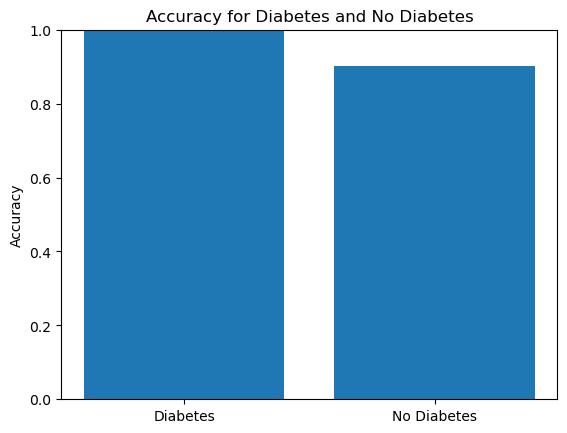

In [10]:
import matplotlib.pyplot as plt
# Create a simple bar plot
labels = ['Diabetes', 'No Diabetes']
accuracies = [accuracy_diabetes, accuracy_no_diabetes]

plt.bar(labels, accuracies)
plt.ylabel('Accuracy')
plt.title('Accuracy for Diabetes and No Diabetes')
plt.ylim(0, 1)  # Set y-axis range to 0-1 for percentages
plt.show()


# Actual Outcomes Counts

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a DataFrame with actual and predicted outcomes
results_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

# Count the occurrences of each class
class_counts = results_df['Actual'].value_counts()

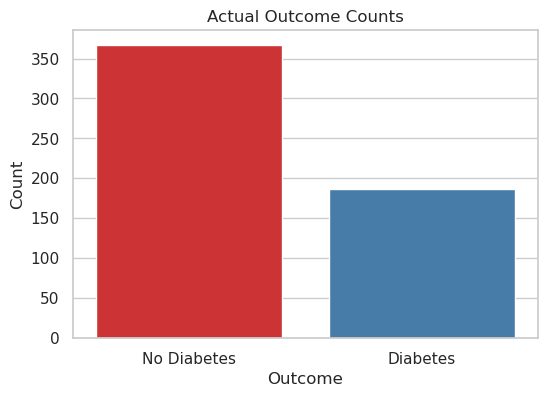

In [12]:
# Create a bar plot to visualize the counts of actual outcomes
plt.figure(figsize=(6, 4))
sns.set(style="whitegrid")
sns.countplot(x='Actual', data=results_df, palette='Set1')
plt.title('Actual Outcome Counts')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['No Diabetes', 'Diabetes'])
plt.show()

# Confusion Matrix

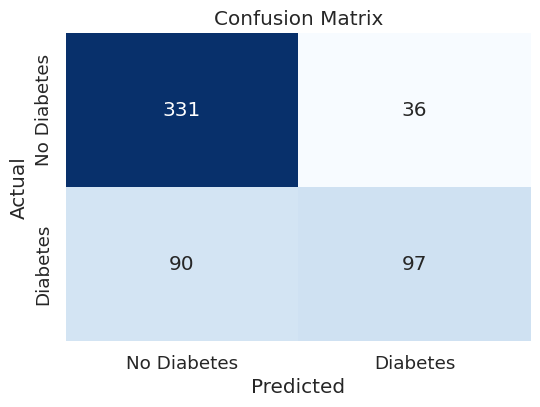

In [13]:
# Create a confusion matrix heatmap
plt.figure(figsize=(6, 4))
sns.set(font_scale=1.2)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['No Diabetes', 'Diabetes'], yticklabels=['No Diabetes', 'Diabetes'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


# Predicted Outcomes for Diabetes and Non Diabetes

In [14]:
# Count instances where actual diabetes cases were predicted as diabetes
diabetes_correct = results_df[(results_df['Actual'] == 1) & (results_df['Predicted'] == 1)].shape[0]
diabetes_incorrect = results_df[(results_df['Actual'] == 1) & (results_df['Predicted'] == 0)].shape[0]

# Count instances where actual no diabetes cases were predicted as no diabetes
no_diabetes_correct = results_df[(results_df['Actual'] == 0) & (results_df['Predicted'] == 0)].shape[0]
no_diabetes_incorrect = results_df[(results_df['Actual'] == 0) & (results_df['Predicted'] == 1)].shape[0]

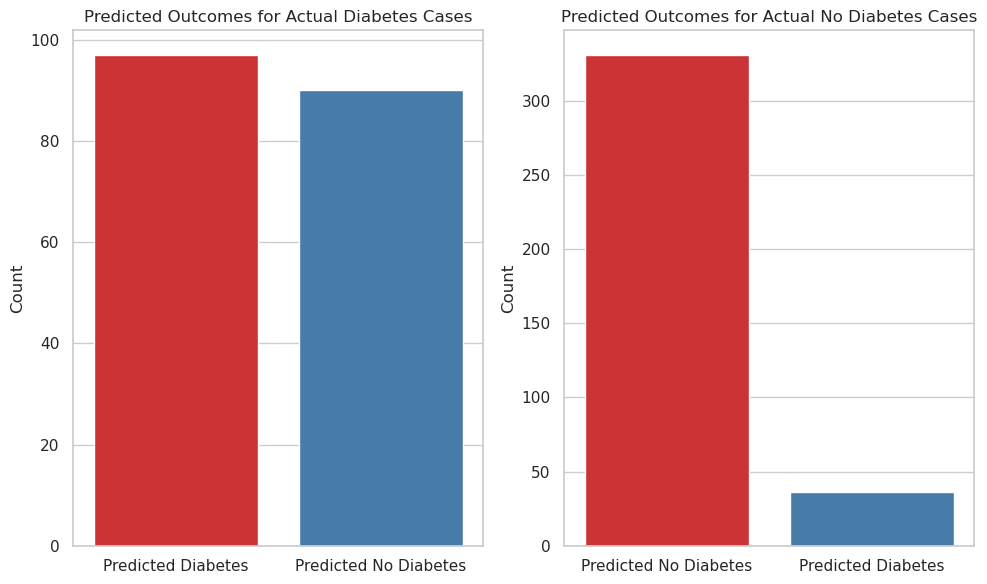

In [15]:

# Create bar plots for diabetes and no diabetes cases
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")

# Bar plot for diabetes cases
plt.subplot(1, 2, 1)
sns.barplot(x=['Predicted Diabetes', 'Predicted No Diabetes'], y=[diabetes_correct, diabetes_incorrect], palette='Set1')
plt.title('Predicted Outcomes for Actual Diabetes Cases')
plt.ylabel('Count')

# Bar plot for no diabetes cases
plt.subplot(1, 2, 2)
sns.barplot(x=['Predicted No Diabetes', 'Predicted Diabetes'], y=[no_diabetes_correct, no_diabetes_incorrect], palette='Set1')
plt.title('Predicted Outcomes for Actual No Diabetes Cases')
plt.ylabel('Count')

plt.tight_layout()
plt.show()
